# Taller B1-T1 · Quantfolio

**Toolkit de extracción multifuente, análisis bursátil y gestión de carteras con simulación de Monte Carlo.**

Este cuaderno es el punto de entrada reproducible del taller: recorre la ingesta de datos (acciones, índices,
criptomonedas y macroeconomía), el modelado de series y carteras, los informes y la simulación Monte Carlo.

Requisitos: haber ejecutado `uv sync` y disponer de conexión a internet (la suite de pruebas no la necesita).


In [1]:
"""Cuaderno de demostración: recorrido reproducible del toolkit Quantfolio."""

from quantfolio import (
    CachedPriceSource,
    FredMacroSource,
    KrakenSource,
    MonteCarloParameters,
    Portfolio,
    YahooFinanceSource,
)

START = "2025-01-02"

#: Cartera de ejemplo: activos y ponderaciones (se normalizan al construirla).
WEIGHTS = {"META": 0.35, "GOOGL": 0.25, "IAG.MC": 0.20, "MC.PA": 0.20}
EQUITIES = list(WEIGHTS)

#: Índices de referencia; el S&P 500 se usa además en el Monte Carlo individual.
SP500 = "^GSPC"
IBEX = "^IBEX"
INDEXES = [SP500, IBEX]

#: Activo usado en la demostración de caché.
CACHE_SAMPLE = EQUITIES[0]

## 1 · Extracción multifuente: acciones e índices (Yahoo Finance)

`get_many()` descarga varias series en lote a partir de una lista de activos. Cada serie se normaliza en un objeto
`PriceSeries` con su ticker, su origen, sus estadísticos automáticos y sus precios limpios.


In [2]:
yahoo = YahooFinanceSource()

equities = yahoo.get_many(EQUITIES, start=START)
indices = yahoo.get_many(INDEXES, start=START)

for ticker, asset in {**equities, **indices}.items():
    print(
        f"{ticker:>8} | {asset.source:<13} | "
        f"{asset.prices.index.min().date()} → {asset.prices.index.max().date()} | "
        f"{len(asset.prices)} observaciones"
    )

    META | Yahoo Finance | 2025-01-02 → 2026-10-30 | 459 observaciones
   GOOGL | Yahoo Finance | 2025-01-02 → 2026-10-30 | 459 observaciones
  IAG.MC | Yahoo Finance | 2025-01-02 → 2026-10-30 | 468 observaciones
   MC.PA | Yahoo Finance | 2025-01-02 → 2026-10-30 | 468 observaciones
   ^GSPC | Yahoo Finance | 2025-01-02 → 2026-10-30 | 459 observaciones
   ^IBEX | Yahoo Finance | 2025-01-02 → 2026-10-30 | 468 observaciones


## 2 · Una segunda API: Kraken

Kraken expone una API pública OHLC sin clave. Su adaptador devuelve **exactamente el mismo objeto interno** que
Yahoo Finance: la capa de análisis es independiente de la API consultada.


In [3]:
kraken = KrakenSource()
btc = kraken.get_prices("BTC/USD", start=START)

print(f"{type(btc).__name__}: {btc.ticker} | {btc.source} | {len(btc.prices)} observaciones")
print(f"Media: {btc.mean_price:,.0f} USD | Desviación típica: {btc.std_price:,.0f} USD")
print(f"¿Mismo objeto interno que las acciones? {type(btc) is type(equities['META'])}")

PriceSeries: BTC/USD | Kraken | 667 observaciones
Media: 89,094 USD | Desviación típica: 17,393 USD
¿Mismo objeto interno que las acciones? True


## 3 · Tipología adicional: tipos de interés (FRED)

`FredMacroSource` descarga indicadores macroeconómicos a través de **ALFRED**, el archivo de *vintages* de
FRED, sin clave de API, y los normaliza en `MacroSeries`. Cada serie registra su `vintage_date`, la fecha
del archivo consultado, y el parámetro `as_of` recupera los valores que se conocían en una fecha pasada,
sin *look-ahead* de revisiones. Aquí se usa el rendimiento del bono estadounidense a 10 años (`DGS10`).


In [4]:
fred = FredMacroSource()
rates = fred.get_series("DGS10", start=START)
pinned = fred.get_series("DGS10", start=START, as_of="2025-03-14")

print(f"{type(rates).__name__}: {rates.series_id} | {rates.source}")
print(f"Últimos valores (%): {rates.values.tail(3).round(2).to_list()}")
print(f"Vintage de la descarga: {rates.vintage_date:%Y-%m-%d}")
print(f"Valores publicados al 2025-03-14 (%): {pinned.values.tail(3).round(2).to_list()}")

MacroSeries: DGS10 | FRED
Últimos valores (%): [5.0, 4.99, 5.05]
Vintage de la descarga: 2026-10-30
Valores publicados al 2025-03-14 (%): [4.28, 4.32, 4.27]


## 4 · Caché CSV local

`CachedPriceSource` envuelve a cualquier proveedor y guarda cada serie en `data/<proveedor>/<ticker>.csv`. El
archivo se reutiliza mientras cubra el intervalo solicitado y su último dato siga vigente; si no, se descarga y se
reemplaza.


In [5]:
cached = CachedPriceSource(YahooFinanceSource(), cache_dir="data")

first = cached.get_prices(CACHE_SAMPLE, start=START)
second = cached.get_prices(CACHE_SAMPLE, start=START)

print("Origen de la primera llamada:", first.source)
print("Origen de la segunda llamada:", second.source)

Origen de la primera llamada: Yahoo Finance (cache)
Origen de la segunda llamada: Yahoo Finance (cache)


## 5 · La cartera

Una cartera es una colección de activos junto con la fracción del capital invertido en cada uno. `Portfolio`
valida las ponderaciones (finitas, no negativas, con clave para cada activo) y las **normaliza** para que sumen 1;
después alinea los calendarios bursátiles por intersección y calcula las métricas ponderadas.


In [6]:
portfolio = Portfolio(
    assets=cached.get_many(EQUITIES, start=START),
    weights=WEIGHTS,
)

print("Pesos normalizados:")
for ticker, weight in portfolio.weights.items():
    print(f"  {ticker}: {weight:.2%}")

print("\nDiagnóstico de alineación temporal:", portfolio.alignment_summary())

print("\nEstadísticos anualizados:")
for name, value in portfolio.summary().items():
    print(f"  {name}: {value:.6f}")

Pesos normalizados:
  META: 35.00%
  GOOGL: 25.00%
  IAG.MC: 20.00%
  MC.PA: 20.00%

Diagnóstico de alineación temporal: {'union_dates': 473, 'common_dates': 454, 'coverage': 0.959830866807611}

Estadísticos anualizados:
  mean_daily_return: 0.000450
  daily_volatility: 0.015338
  annualized_return_approx: 0.113298
  annualized_volatility: 0.243482


## 6 · Informe Markdown parametrizable

`report()` genera composición, métricas, calidad de los datos y advertencias de riesgo derivadas del estado real
de la cartera (cobertura de alineación, concentración y longitud de la muestra).


In [7]:
from IPython.display import Markdown

Markdown(portfolio.report())

# Informe de la cartera

## 1. Composición

| Activo | Peso |
|---|---:|
| META | 35.00% |
| GOOGL | 25.00% |
| IAG.MC | 20.00% |
| MC.PA | 20.00% |

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | 0.0450% |
| Volatilidad diaria | 1.5338% |
| Rentabilidad anualizada aproximada | 11.33% |
| Volatilidad anualizada | 24.35% |

## 3. Calidad de los datos

- Activos: 4
- Fechas en la unión de calendarios: 473
- Fechas comunes a todos los activos: 454
- Cobertura tras la alineación: 96.0%
- Observaciones de rentabilidad: 453

## 4. Advertencias de riesgo

- Las rentabilidades históricas no garantizan resultados futuros.
- La simulación de Monte Carlo depende de los supuestos de rentabilidad y volatilidad.

In [8]:
# El informe es parametrizable: se pueden omitir secciones o cambiar la anualización.
print(portfolio.report(include_warnings=False))

# Informe de la cartera

## 1. Composición

| Activo | Peso |
|---|---:|
| META | 35.00% |
| GOOGL | 25.00% |
| IAG.MC | 20.00% |
| MC.PA | 20.00% |

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | 0.0450% |
| Volatilidad diaria | 1.5338% |
| Rentabilidad anualizada aproximada | 11.33% |
| Volatilidad anualizada | 24.35% |

## 3. Calidad de los datos

- Activos: 4
- Fechas en la unión de calendarios: 473
- Fechas comunes a todos los activos: 454
- Cobertura tras la alineación: 96.0%
- Observaciones de rentabilidad: 453


## 7 · Panel analítico de visualizaciones

`plots_report()` muestra la evolución de precios, la rentabilidad acumulada por activo, la matriz de correlación y
la evolución del valor de la cartera (base 100).


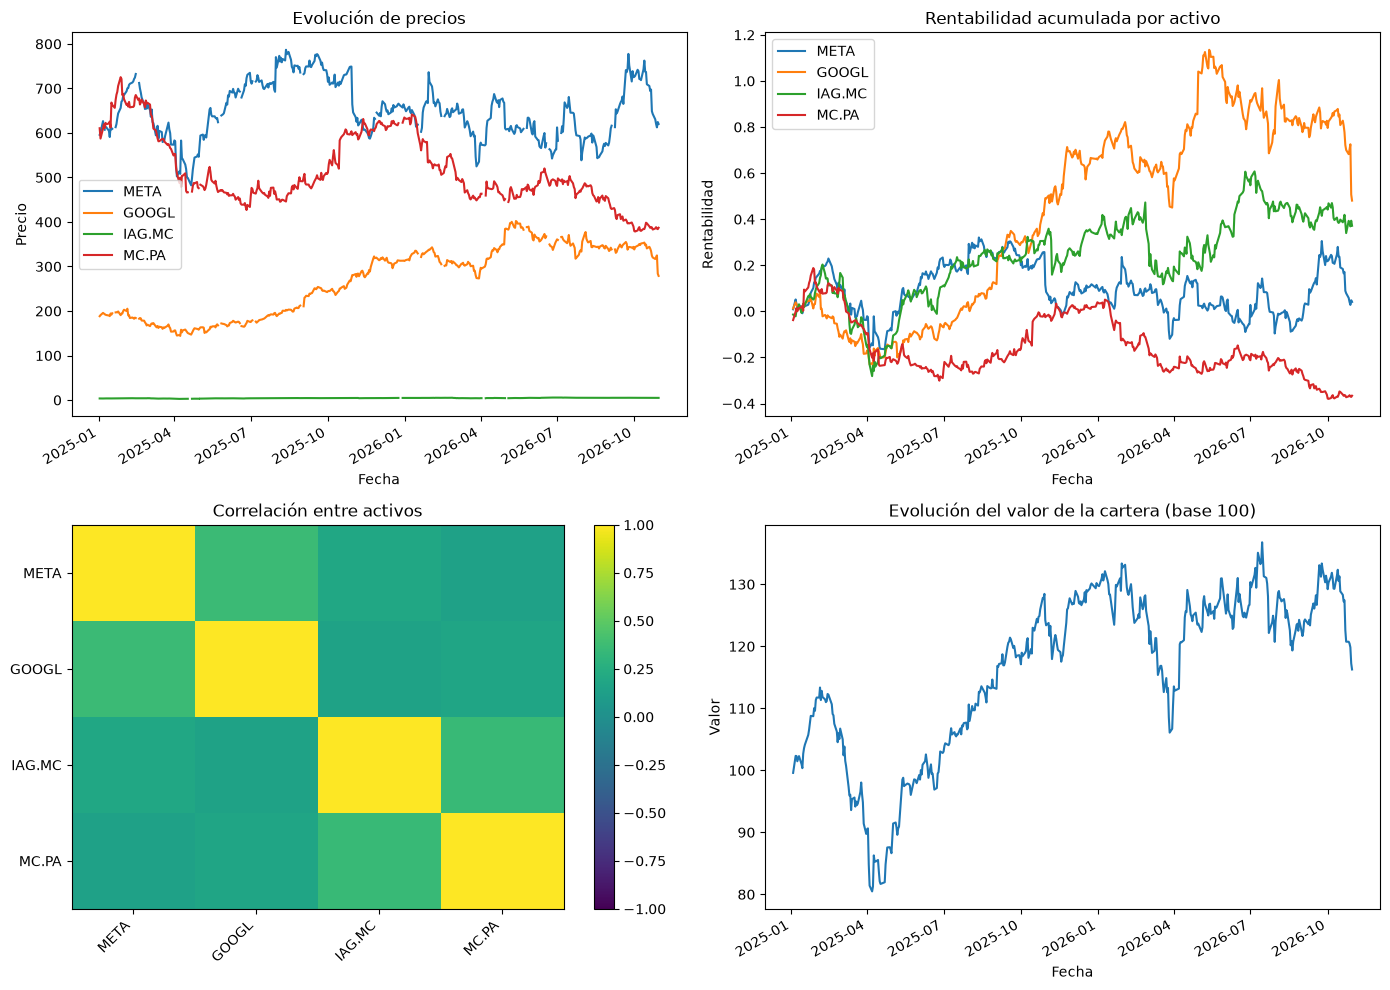

In [9]:
portfolio.plots_report()

## 8 · Monte Carlo de la cartera

La simulación modela la cartera con un movimiento browniano geométrico parametrizable
(`MonteCarloParameters`): número de trayectorias, horizonte, valor inicial, supuestos de rentabilidad y volatilidad,
y semilla. Por defecto, los supuestos se estiman de las rentabilidades históricas.


In [10]:
simulations = portfolio.simulate_monte_carlo(
    MonteCarloParameters(n_paths=2_000, horizon=252, seed=42)
)

final_values = simulations.iloc[-1]
print(f"Valor inicial: {simulations.iloc[0, 0]:,.0f}")
print(final_values.describe(percentiles=[0.05, 0.5, 0.95]).round(2))

Valor inicial: 10,000
count     2000.00
mean     11198.39
std       2826.22
min       5097.60
5%        7251.73
50%      10780.95
95%      16734.83
max      23241.58
Name: 252, dtype: float64


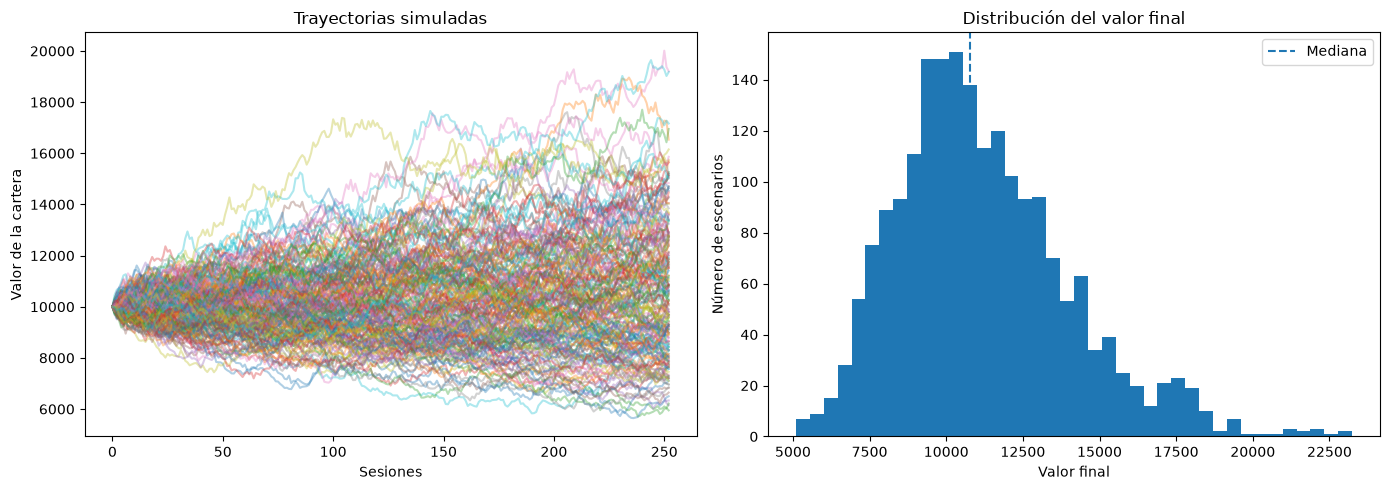

In [11]:
portfolio.plot_simulation(simulations, max_paths=200)

## 9 · Monte Carlo de un activo con supuestos propios

La misma simulación está disponible en `PriceSeries`. Aquí se simula el S&P 500 asumiendo un 8 % de rentabilidad
anual y un 18 % de volatilidad, en lugar de los valores históricos, y partiendo del último cierre observado.


In [12]:
scenario = indices[SP500].simulate_monte_carlo(
    MonteCarloParameters(
        n_paths=1_000,
        horizon=252,
        return_assumption=0.08,
        volatility_assumption=0.18,
        seed=7,
    )
)

print(f"Punto de partida: {scenario.iloc[0, 0]:,.0f} (último cierre de {SP500})")
print(f"Mediana a un año: {scenario.iloc[-1].median():,.0f}")

Punto de partida: 7,579 (último cierre de ^GSPC)
Mediana a un año: 8,207


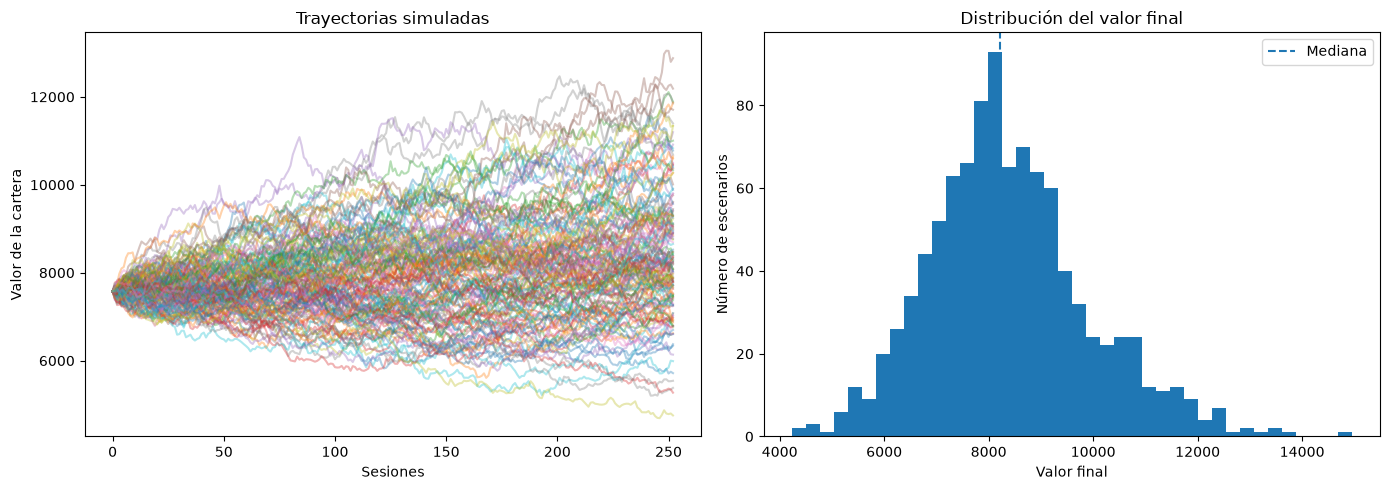

In [13]:
indices[SP500].plot_simulation(scenario, max_paths=150)

## 10 · Calidad del código y siguientes pasos

Los controles de calidad del proyecto se ejecutan con:

```console
uv run ruff check .
uv run ruff format --check .
uv run mypy src tests
uv run pytest
```

- La biblioteca vive en `src/quantfolio/` (solo código importable y probado); este cuaderno y la caché `data/` no
  forman parte del paquete.
- Análisis estático con SonarQube (perfiles estrictos `Python Strict`/`IPython Strict` y *quality gate*
  `Quantfolio Strict`, sin ninguna incidencia): los pasos están documentados en el README.
- Diagrama de arquitectura UML y de flujo: [`docs/architecture.md`](../docs/architecture.md).
- Correspondencia completa con el enunciado del taller: README del repositorio.

